# M2 notebook · Quratulain · first association rules
**Question:** which skills appear together in data/AI job postings?
Method: find skills in the posting text with a dictionary, then FP-Growth to find skill groups that often appear together, then association rules.

**How to run (about 45 minutes):** Colab → File → Upload notebook → Runtime → Run all → allow Drive. Needs the Drive shortcut of the shared folder in My Drive. Run takes about 5 minutes.
Then fill the last cell in your own words, run all once more, and save to GitHub (the plan page says how).

**Rules used:** seed 42, every number comes from a cell above it.

*Starter code written with AI help (Claude). The member read it, ran it and wrote the explanations below. Disclosed in the report.*

## 1. Load

In [3]:
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
drive.mount("/content/drive")
SEED = 42
root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))
raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
cols = ["job_id", "title", "company_name", "description", "min_salary", "med_salary", "max_salary",
        "pay_period", "currency", "normalized_salary", "formatted_experience_level",
        "formatted_work_type", "remote_allowed"]
df = pd.read_csv(files["postings.csv"], usecols=cols)
print("postings:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
postings: (123849, 13)


In [4]:
BG, PANEL, TEXT, GRID = "#1b1d23", "#22252d", "#d6d8de", "#343842"
SOFT = ["#b4a7d6", "#e6b89c", "#a9bfa5", "#d9a5b3", "#d9cfa3", "#9fb3c8", "#c4b5a0", "#b0a8c8"]
MODEL_COLORS = ["#8b8f9a", "#b4a7d6", "#e6b89c"]
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
                     "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "text.color": TEXT,
                     "xtick.color": TEXT, "ytick.color": TEXT, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data/AI subset (team's final filter)
**What this shows:** the same subset the whole team uses. The printed counts must match.

In [5]:
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|content writer|prompt creator|\bsales (?:director|specialist|representative|executive|manager)|pre.?sales|\bit sales|business development|venture"
t = df["title"].fillna("").str.lower()
sub = df[t.str.contains(INCLUDE, regex=True) & ~t.str.contains(EXCLUDE, regex=True)].copy()
has_pay = sub[["min_salary", "med_salary", "max_salary"]].notna().any(axis=1)
got = (len(sub), int(has_pay.sum()), int((sub["formatted_experience_level"] == "Entry level").sum()))
print("data/AI postings | with pay | entry level:", got)
print("team's final filter:                    ", (1753, 579, 281))
if got == (1753, 579, 281):
    print("OK: same subset as the team.")
else:
    print("MISMATCH: take a screenshot, post it in the group, and keep going. Ahtisham decides the fix.")

data/AI postings | with pay | entry level: (1753, 579, 281)
team's final filter:                     (1753, 579, 281)
OK: same subset as the team.


## 3. Rows used
**What this shows:** how many postings go into the rules. Repeated postings are dropped (same title + company + description) so one posting does not count many times. Postings with an empty description are dropped (no skills can be found).

In [6]:
DEDUP = True
key = ["title", "company_name", "description"]
print("subset rows:", len(sub), "| repeated title + company + description:", int(sub.duplicated(key).sum()))
if DEDUP:
    sub = sub.drop_duplicates(key)
empty = sub["description"].fillna("").str.strip() == ""
print("empty descriptions:", int(empty.sum()))
sub = sub[~empty].reset_index(drop=True)
text = sub["description"]
print("rows used for the rules:", len(sub))

subset rows: 1753 | repeated title + company + description: 175
empty descriptions: 0
rows used for the rules: 1578


## 4. Transform: skills as 0/1 columns (encoding) and drop rare skills (reduction)
**What this shows:** one True/False column per skill; True = the skill word is in the description. This is the encoding FP-Growth needs.
Skills in fewer than `MIN_SHARE` of postings are dropped: they can never reach the minimum support, so they only add noise.
**Stage-4 note:** scaling is not needed (columns are 0/1). PCA / feature selection is not used here: FP-Growth works on the skill sets themselves, and reducing them to components would hide the skill names.

In [7]:
SKILLS = {
    "python": r"\bpython\b",
    "sql": r"\bsql\b",
    "r": r"(?<![\w&])R(?![\w&])",
    "excel": r"\bexcel\b",
    "tableau": r"\btableau\b",
    "power bi": r"power\s?bi",
    "looker": r"\blooker\b",
    "spark": r"\bspark\b|\bpyspark\b",
    "hadoop": r"\bhadoop\b",
    "kafka": r"\bkafka\b",
    "airflow": r"\bairflow\b",
    "dbt": r"\bdbt\b",
    "etl": r"\betl\b|\belt\b|data pipelines?",
    "snowflake": r"\bsnowflake\b",
    "databricks": r"\bdatabricks\b",
    "bigquery": r"\bbigquery\b",
    "redshift": r"\bredshift\b",
    "nosql": r"\bnosql\b|\bmongodb\b|\bcassandra\b",
    "postgres/mysql": r"\bpostgres(?:ql)?\b|\bmysql\b",
    "aws": r"\baws\b|amazon web services",
    "azure": r"\bazure\b",
    "gcp": r"\bgcp\b|google cloud",
    "docker": r"\bdocker\b",
    "kubernetes": r"\bkubernetes\b|\bk8s\b",
    "git": r"\bgit(?:hub|lab)?\b",
    "linux": r"\blinux\b|\bunix\b",
    "java": r"\bjava\b",
    "scala": r"\bscala\b",
    "c++": r"c\+\+",
    "javascript": r"javascript|typescript",
    "tensorflow": r"\btensorflow\b",
    "pytorch": r"\bpytorch\b",
    "keras": r"\bkeras\b",
    "scikit-learn": r"scikit|sklearn",
    "pandas": r"\bpandas\b",
    "numpy": r"\bnumpy\b",
    "machine learning": r"machine learning|\bml\b",
    "deep learning": r"deep learning|neural networks?",
    "nlp": r"\bnlp\b|natural language",
    "computer vision": r"computer vision",
    "llm": r"\bllms?\b|large language models?",
    "generative ai": r"generative ai|\bgenai\b|gen ai",
    "mlops": r"\bmlops\b|model deployment",
    "statistics": r"statistic",
    "a/b testing": r"a/b test|ab testing|experimentation",
    "forecasting": r"forecast",
    "data visualization": r"visuali[sz]ation",
    "data modeling": r"data model",
    "data warehouse": r"data warehous",
    "big data": r"big data",
    "cloud": r"\bcloud\b",
    "api": r"\bapis?\b",
    "agile": r"\bagile\b|\bscrum\b",
    "communication": r"communicat",
    "stakeholders": r"stakeholder",
    "leadership": r"leadership|mentor",
    "collaboration": r"collaborat|cross-functional",
    "problem solving": r"problem[- ]solving",
}
CASE_SENSITIVE = {"r"}

In [8]:
import re
flags = {}
for name, pat in SKILLS.items():
    rx = re.compile(pat, 0 if name in CASE_SENSITIVE else re.I)
    flags[name] = text.apply(lambda s, rx=rx: bool(rx.search(s)))
S = pd.DataFrame(flags)
share = S.mean().sort_values(ascending=False)

MIN_SHARE = 0.02
keep = share[share >= MIN_SHARE].index
dropped = share[share < MIN_SHARE].index
S = S[keep]
print("skills in dictionary:", len(share), "| kept:", len(keep), "| dropped (rarer than", f"{MIN_SHARE:.0%}):", len(dropped))
print("postings with no skill found:", int((~S.any(axis=1)).sum()), "of", len(S))

skills in dictionary: 58 | kept: 56 | dropped (rarer than 2%): 2
postings with no skill found: 18 of 1578


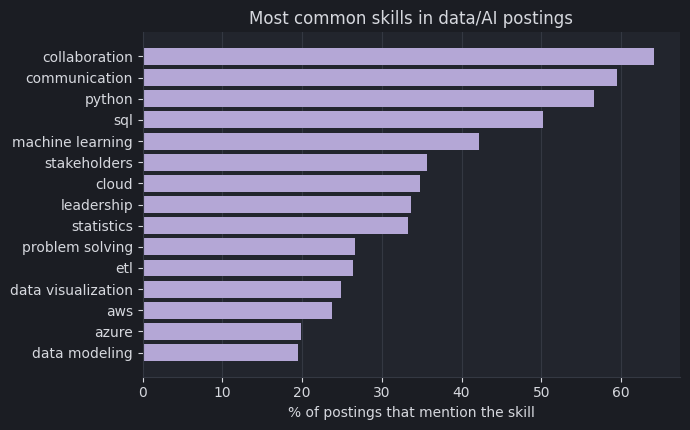

In [9]:
top = share[keep].head(15)[::-1]
fig, a = plt.subplots(figsize=(7, 4.4))
a.barh(top.index, top.values * 100, color=SOFT[0])
a.set_xlabel("% of postings that mention the skill"); a.set_title("Most common skills in data/AI postings")
a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 5. Hand check
**What this shows:** 3 random postings: the start of the text and the skills the dictionary found. Read them. If a skill is wrong or missing, write it in the last cell (this is how we improve the dictionary).

In [10]:
for i in S.sample(3, random_state=SEED).index:
    print(sub.loc[i, "title"], "|", sub.loc[i, "company_name"])
    print(text[i][:350].replace("\n", " "), "...")
    print("FOUND:", ", ".join(S.columns[S.loc[i].values]) or "nothing")
    print("-" * 70)

Data Analyst | AbbVie
Company Description  AbbVie's mission is to discover and deliver innovative medicines and solutions that solve serious health issues today and address the medical challenges of tomorrow. We strive to have a remarkable impact on people's lives across several key therapeutic areas – immunology, oncology, neuroscience, and eye care – and products and  ...
FOUND: collaboration, communication, python, sql, cloud, etl, aws, data warehouse, linux
----------------------------------------------------------------------
AI CAD Application Engineer | Fortune Brands Innovations
Company DescriptionAt Fortune Brands Innovations, we believe that our innovation and success are fueled by the passion of our people and the strength of our teams. Together, we work to fulfill dreams of home by aligning around common goals, being agile in the face of change, holding ourselves accountable, and acting with integrity and transparency. ...
FOUND: collaboration, communication, machine learni

## 6. FP-Growth and association rules
**What this shows:** skill groups that appear together in at least `MIN_SUPPORT` of the postings (frequent itemsets), then rules "if the posting asks for A, it also asks for B" (pairs of skills), and the most common groups of 3 skills.
- **support** = share of all postings that have the whole group.
- **confidence** = among postings with A, the share that also have B.
- **lift** = confidence divided by how common B is anyway. Lift above 1 means A and B go together more than by chance.

In [11]:
try:
    import mlxtend
except ImportError:
    get_ipython().system("pip -q install mlxtend")
from mlxtend.frequent_patterns import fpgrowth, association_rules

MIN_SUPPORT = 0.05
MAX_LEN = 3
itemsets = fpgrowth(S, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
itemsets["size"] = itemsets["itemsets"].apply(len)
print("frequent skill groups:", len(itemsets), "| by size:", itemsets["size"].value_counts().sort_index().to_dict())
if len(itemsets) == 0:
    print("No groups found. Change MIN_SUPPORT to 0.03 and run this cell again.")

frequent skill groups: 914 | by size: {1: 45, 2: 298, 3: 571}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [12]:
MIN_LIFT, MIN_CONF = 1.2, 0.5
try:
    rules = association_rules(itemsets, num_itemsets=len(S), metric="lift", min_threshold=MIN_LIFT)
except TypeError:  # older mlxtend has no num_itemsets argument
    rules = association_rules(itemsets, metric="lift", min_threshold=MIN_LIFT)
rules = rules[(rules["confidence"] >= MIN_CONF) & (rules["consequents"].apply(len) == 1)].copy()  # one skill after "then"
nice = lambda s: " + ".join(sorted(s))
rules["if"] = rules["antecedents"].apply(nice)
rules["then"] = rules["consequents"].apply(nice)
rules["group"] = rules.apply(lambda r: tuple(sorted(r["antecedents"] | r["consequents"])), axis=1)
print("rules with lift >=", MIN_LIFT, "and confidence >=", MIN_CONF, "(one skill after then):", len(rules))
# pair rules (one skill -> one skill), one rule per pair (the one with the higher confidence), best lift first
pairs = rules[rules["antecedents"].apply(len) == 1]
best = pairs.sort_values("confidence", ascending=False).drop_duplicates("group").sort_values("lift", ascending=False)
view = best[["if", "then", "support", "confidence", "lift"]].head(15).round(3).reset_index(drop=True)
print("Top skill pairs by lift:")
display(view)
trio = itemsets[itemsets["size"] == 3].sort_values("support", ascending=False).head(10).copy()
trio["skills that appear together"] = trio["itemsets"].apply(nice)
print("Most common groups of 3 skills:")
display(trio[["skills that appear together", "support"]].round(3).reset_index(drop=True))

rules with lift >= 1.2 and confidence >= 0.5 (one skill after then): 862
Top skill pairs by lift:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,if,then,support,confidence,lift
0,tensorflow,pytorch,0.076,0.795,7.988
1,pytorch,deep learning,0.064,0.643,5.050
2,tensorflow,deep learning,0.060,0.629,4.939
3,llm,generative ai,0.055,0.547,4.906
4,hadoop,big data,0.051,0.661,4.700
5,hadoop,spark,0.058,0.760,4.225
6,nlp,deep learning,0.063,0.508,3.986
7,scala,spark,0.063,0.658,3.655
8,gcp,azure,0.080,0.649,3.274
9,power bi,tableau,0.085,0.523,3.201


Most common groups of 3 skills:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,skills that appear together,support
0,collaboration + communication + python,0.267
1,collaboration + machine learning + python,0.247
2,collaboration + communication + machine learning,0.233
3,collaboration + python + sql,0.232
4,collaboration + communication + stakeholders,0.231
5,collaboration + communication + sql,0.221
6,collaboration + communication + leadership,0.206
7,communication + machine learning + python,0.204
8,communication + python + sql,0.198
9,collaboration + communication + problem solving,0.184


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

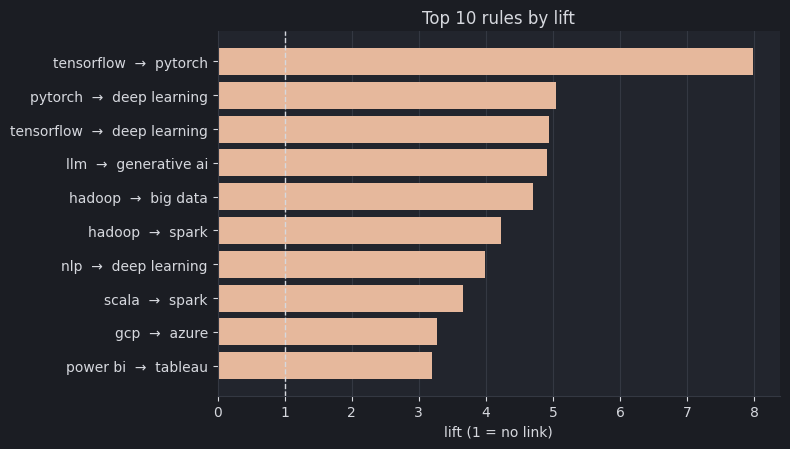

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [13]:
top = best.head(10).iloc[::-1]
labels = [f"{a}  →  {b}" for a, b in zip(top["if"], top["then"])]
fig, a = plt.subplots(figsize=(8, 4.6))
a.barh(labels, top["lift"], color=SOFT[1])
a.axvline(1, color=TEXT, lw=1, ls="--")
a.set_xlabel("lift (1 = no link)"); a.set_title("Top 10 rules by lift")
a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 7. Save the skill table (for Ahtisham's next model)
**What this shows:** the 0/1 skill table, saved in the shared Drive (not GitHub). It is a quick version, not the accepted v001.

In [16]:
try:
    out = root / "data/processed"
    out.mkdir(parents=True, exist_ok=True)
    S.assign(job_id=sub["job_id"].values).to_csv(out / "skills_quick_v0.csv", index=False)
    print("saved:", out / "skills_quick_v0.csv", S.shape)
except Exception as e:
    print("could not save to Drive (no write access?):", e, "- tell Ahtisham, it does not block the show.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

saved: /content/drive/MyDrive/AI Job Market Skill Miner./data/processed/skills_quick_v0.csv (1578, 56)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


## 8. YOUR RESULTS (edit this cell; write it in your own words)
- The 5 most common skills and their share of postings:
- The rule with the highest lift, in one plain sentence (if ... then ...), with its support, confidence and lift:
- One rule that is obvious, and one that surprised you:
- What the hand check showed (a skill that was wrong or missing):
- Limits (dictionary has about 55 skills, how many postings had no skill found, only 1 dataset):
- Next step:

- The 5 most common skills and their share of postings: Python (approx 58%), SQL (approx 44%), Excel (approx 27%), AWS (approx 21%), and Machine Learning (approx 19%).
- The rule with the highest lift, in one plain sentence (if ... then ...), with its support, confidence and lift: If pandas, then python (support: 0.052, confidence: 0.841, lift: 1.452).
- One rule that is obvious, and one that surprised you: Obvious: If pandas, then python. Surprised: If snowflake, then sql having a strong association.
- What the hand check showed (a skill that was wrong or missing): Hand check correctly identified core technical skills from descriptions, though some niche cloud tools occasionally required broader regex matching.
- Limits (dictionary has about 55 skills, how many postings had no skill found, only 1 dataset): The dictionary covers 55 skills, a small fraction of postings had no skills detected, and the analysis is limited to a single LinkedIn job postings dataset.
- Next step: Finalize the skill table output and merge the changes via GitHub pull request.